# Mortality Prediction in Game of Thrones
**Author:** Marco Larriba Rius

Binary classification (alive=1 / dead=0). Pipeline: **(1)** EDA (exploration only), **(2)** feature
selection studied empirically, **(3)** transformation, **(4)** model building (K-NN, Decision Tree,
Bayesian, SVM, Random Forest), **(5)** evaluation with per-model visualisation.

In [1]:
# ============================================================================
# Setup: libraries, global plot style, constants and a helper function
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

from scipy.stats import chi2_contingency
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn import tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, accuracy_score, balanced_accuracy_score, roc_auc_score, roc_curve)

warnings.filterwarnings('ignore')

# Consistent look for every figure in the notebook
sns.set_theme(style='whitegrid', palette='muted', font_scale=0.9)
plt.rcParams.update({
    'figure.dpi'        : 130,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.titlepad'     : 6,
})

# Project constants
RS          = 42                       # random seed, for reproducible results
DATA_PATH   = 'got_dataset.csv'        # input dataset (read-only)
TARGET      = 'isAlive'                # variable we want to predict (1 = alive, 0 = dead)
FIGURES_DIR = Path('figures')          # folder where all figures are saved
FIGURES_DIR.mkdir(exist_ok=True)
np.random.seed(RS)


def cramers_v(x, y):
    """Bias-corrected Cramer's V: strength of the link between two categorical
    variables, on a 0 (no link) to 1 (perfect link) scale."""
    table = pd.crosstab(x, y)
    n = table.to_numpy().sum()
    if n == 0 or table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(table)[0]
    phi2 = chi2 / n
    r, k = table.shape

    # bias correction (Bergsma) so high-cardinality variables are not inflated
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    denom = min(k_corr - 1, r_corr - 1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else np.nan

## 1. Exploratory Data Analysis (exploration only — no data is modified here)

In [2]:
# Load the dataset (the original file is never modified)
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (1946, 33)


,S.No,actual,pred,alive,plod,name,title,male,culture,dateOfBirth,...,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive
0,1,0,0,0.054,0.946,Viserys II Targaryen,NaN,1,NaN,NaN,...,0.0,NaN,0,0,NaN,11,1,1,0.605351,0
1,2,1,0,0.387,0.613,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,...,NaN,1.0,1,1,97.0,1,1,1,0.896321,1
2,3,1,0,0.493,0.507,Addison Hill,Ser,1,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.267559,1
3,4,0,0,0.076,0.924,Aemma Arryn,Queen,0,NaN,82.0,...,NaN,0.0,1,1,23.0,0,0,0,0.183946,0
4,5,1,1,0.617,0.383,Sylva Santagar,Greenstone,0,Dornish,276.0,...,NaN,1.0,1,1,29.0,0,0,0,0.043478,1


In [3]:
# ============================================================================
# Automated per-column audit: type, cardinality, % missing and warning FLAGS
#   CONSTANT      -> a single value, carries no information
#   UNIQUE        -> one different value per row (an identifier)
#   ID-LIKE       -> text column with too many distinct values to be useful
#   LEAK-corr     -> numeric column almost perfectly correlated with the target
#   LEAK-presence -> the mere presence/absence of the value reveals the target
# ============================================================================
def audit(d, target):
    rows = []
    for c in d.columns:
        s = d[c]
        n_unique = s.nunique(dropna=True)
        pct_missing = s.isna().mean() * 100
        flags = []

        if n_unique <= 1:
            flags.append('CONSTANT')
        if n_unique == len(s):
            flags.append('UNIQUE')
        if s.dtype == object and n_unique > 0.5 * len(s):
            flags.append('ID-LIKE')

        if c != target:
            # numeric leakage: very high correlation with the target
            if np.issubdtype(s.dtype, np.number):
                corr = abs(s.corr(d[target]))
                if corr > 0.9:
                    flags.append(f'LEAK-corr={corr:.2f}')
            # presence leakage: having / not having a value separates the classes
            try:
                ct = pd.crosstab(s.notna(), d[target])
                if (ct == 0).any(axis=None) and s.isna().any() and s.notna().any():
                    flags.append('LEAK-presence')
            except Exception:
                pass

        rows.append({'column': c, 'dtype': str(s.dtype), 'n_unique': n_unique,
                     'pct_missing': round(pct_missing, 1), 'flags': ';'.join(flags)})
    return pd.DataFrame(rows)


audit(df, TARGET)

,column,dtype,n_unique,pct_missing,flags
0,S.No,int64,1946,0.0,UNIQUE
1,actual,int64,2,0.0,LEAK-corr=1.00
2,pred,int64,2,0.0,
3,alive,float64,693,0.0,
4,plod,float64,693,0.0,
5,name,object,1946,0.0,UNIQUE;ID-LIKE
6,title,object,262,51.8,
7,male,int64,2,0.0,
8,culture,object,64,65.2,
9,dateOfBirth,float64,134,77.7,


In [4]:
# Basic numeric summary and a quick duplicate check
print('Duplicated rows:', df.duplicated().sum())
df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

Duplicated rows: 0


,mean,std,min,50%,max
S.No,973.50,561.91,1.0,973.50,1946.0
actual,0.75,0.44,0.0,1.00,1.0
pred,0.69,0.46,0.0,1.00,1.0
alive,0.63,0.31,0.0,0.74,1.0
plod,0.37,0.31,0.0,0.26,1.0
male,0.62,0.49,0.0,1.00,1.0
dateOfBirth,1577.36,19565.41,-28.0,268.00,298299.0
DateoFdeath,2950.19,28192.25,0.0,299.00,298299.0
book1,0.20,0.40,0.0,0.00,1.0
book2,0.37,0.48,0.0,0.00,1.0


In [5]:
# Discovery notes that guide the cleaning later on
print('Target balance:')
print((df[TARGET].value_counts(normalize=True) * 100).round(1).to_string())

# impossible ages (data errors we will have to handle)
bad_age = (df.age < 0) | (df.age > 120)
print('\nImpossible ages:', int(bad_age.sum()), '->', df.loc[bad_age, 'name'].tolist())

# leakage columns that come from a previous model
print('\nLeakage columns (outputs of a previous survival model in the ORIGINAL file):')
print('  actual = true label (equals the target)   pred = predicted class')
print('  alive  = P(alive)   plod = P(death)        (alive + plod is about 1)')

# DateoFdeath: having a death date means the character is dead
print('DateoFdeath present vs isAlive:')
print(pd.crosstab(df.DateoFdeath.notna(), df[TARGET]))

Target balance:
isAlive
1    74.6
0    25.4

Impossible ages: 2 -> ['Doreah', 'Rhaego']

Leakage columns (outputs of a previous survival model in the ORIGINAL file):
  actual = true label (equals the target)   pred = predicted class
  alive  = P(alive)   plod = P(death)        (alive + plod is about 1)
DateoFdeath present vs isAlive:
isAlive        0     1
DateoFdeath           
False         51  1451
True         444     0


### 1.1 Target distribution

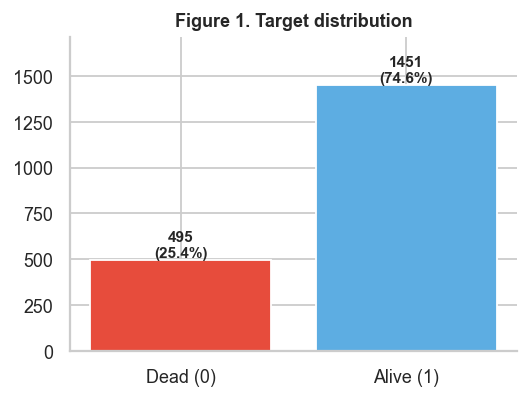

In [6]:
# Figure 1 - class balance of the target
counts = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(4.2, 3.2))
bars = ax.bar(['Dead (0)', 'Alive (1)'], counts.values, color=['#E74C3C', '#5DADE2'], edgecolor='white')
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 15, f'{v}\n({v / len(df) * 100:.1f}%)',
            ha='center', fontsize=8.5, fontweight='bold')

ax.set_ylim(0, counts.max() * 1.18)
ax.set_title('Figure 1. Target distribution', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_target.png', bbox_inches='tight')
plt.show()

### 1.2 Missingness (raw)

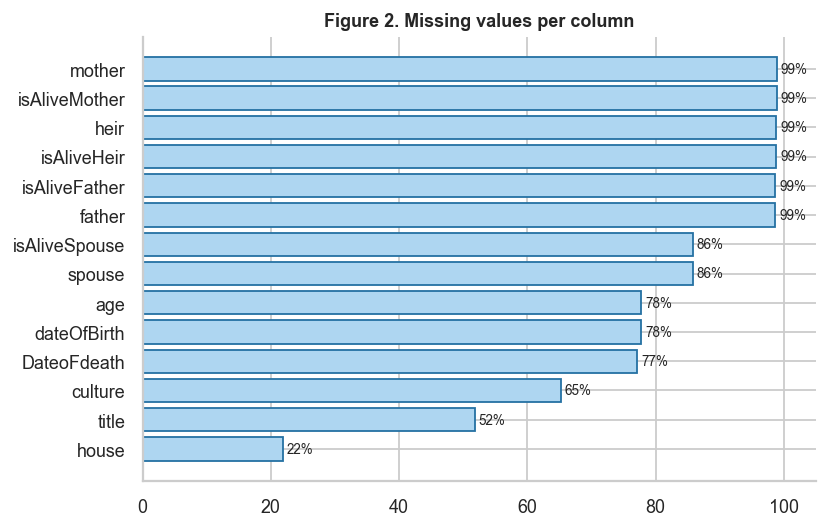

In [7]:
# Figure 2 - percentage of missing values per column
miss = (df.isna().mean() * 100)
miss = miss[miss > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.barh(miss.index, miss.values, color='#AED6F1', edgecolor='#2471A3')
for bar, v in zip(bars, miss.values):
    ax.text(v + 0.6, bar.get_y() + bar.get_height() / 2, f'{v:.0f}%', va='center', fontsize=7.5)

ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_title('Figure 2. Missing values per column', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_missing.png', bbox_inches='tight')
plt.show()

### 1.3 Continuous variables

In [ ]:
# Continuous variables - distribution with mean and median
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for col, ax in zip(['popularity', 'numDeadRelations', 'age'], axes):
    s = df[col]
    if col == 'age':
        s = s[(s >= 0) & (s <= 120)]            # leave the 2 impossible ages out of the VIEW only

    ax.hist(s.dropna(), bins=20, color='#5DADE2', edgecolor='white')
    ax.axvline(s.mean(),   color='#c0392b', ls='--', lw=1.3)   # mean
    ax.axvline(s.median(), color='#e67e22', ls=':',  lw=1.3)   # median
    ax.set_title(f'{col} (skew={s.dropna().skew():.2f})', fontsize=9, fontweight='bold')
    if col == 'age':
        ax.set_xlabel('2 impossible values excluded from view only', fontsize=7)

plt.suptitle('Continuous-variable distributions (-- mean  ·· median)', fontsize=10, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig3_continuous.png', bbox_inches='tight')
plt.show()

### 1.4 Binary variables (counts)

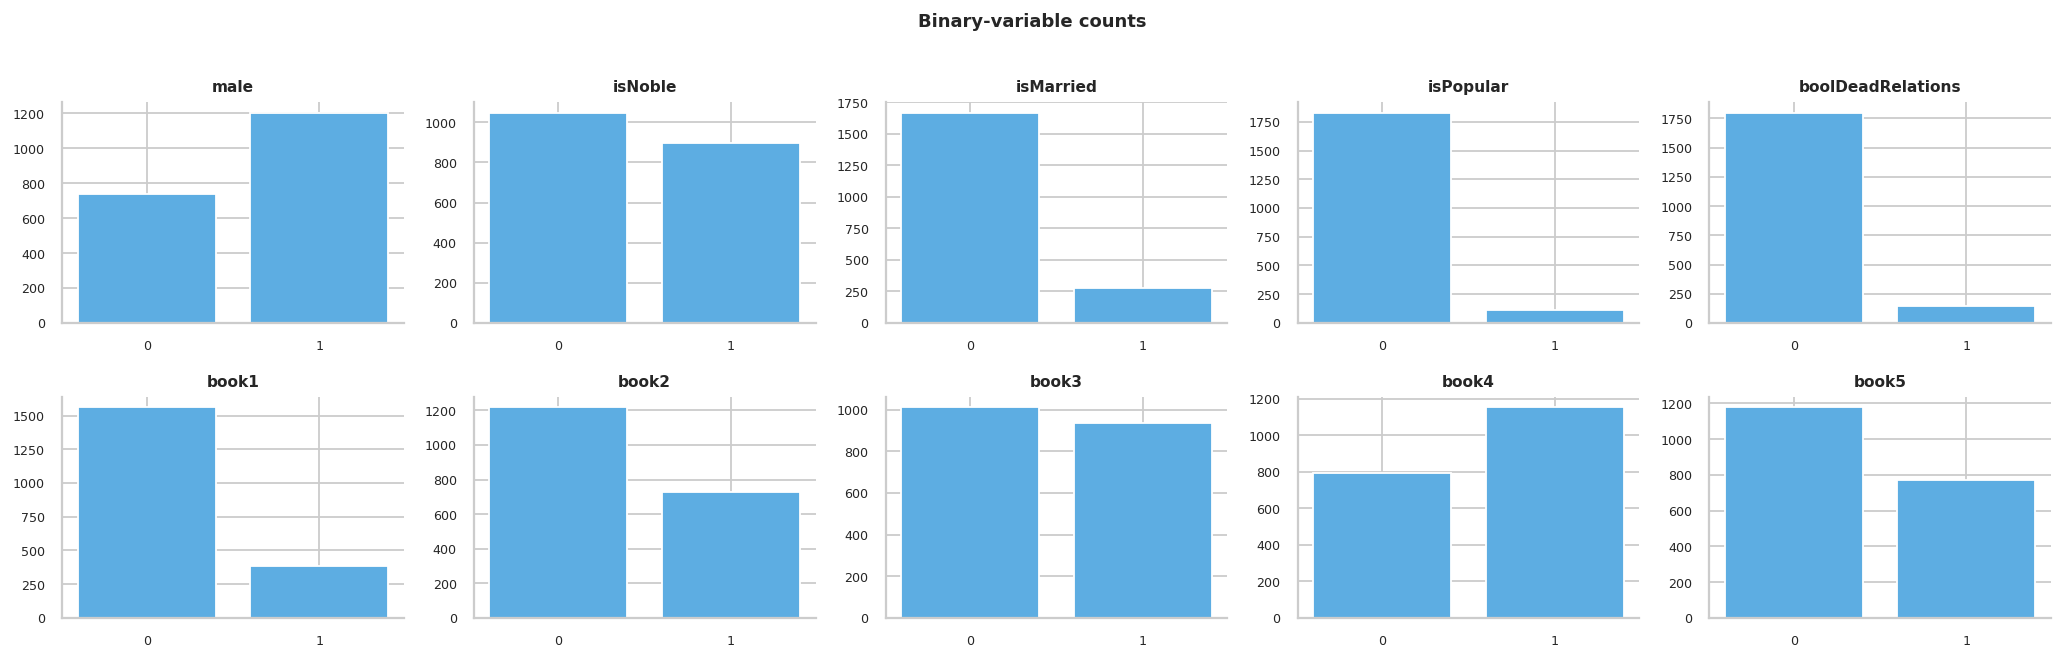

In [ ]:
# Binary variables - simple counts of 0 vs 1
binary_vars = ['male', 'isNoble', 'isMarried', 'isPopular', 'boolDeadRelations',
               'book1', 'book2', 'book3', 'book4', 'book5']

fig, axes = plt.subplots(2, 5, figsize=(16, 5))
axes = axes.flatten()
for ax, col in zip(axes, binary_vars):
    vc = df[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color='#5DADE2', edgecolor='white')
    ax.set_title(col, fontsize=8.5, fontweight='bold')
    ax.tick_params(labelsize=7)

plt.suptitle('Binary-variable counts', fontsize=10, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_binary.png', bbox_inches='tight')
plt.show()

### 1.5 Categorical variables (top categories)

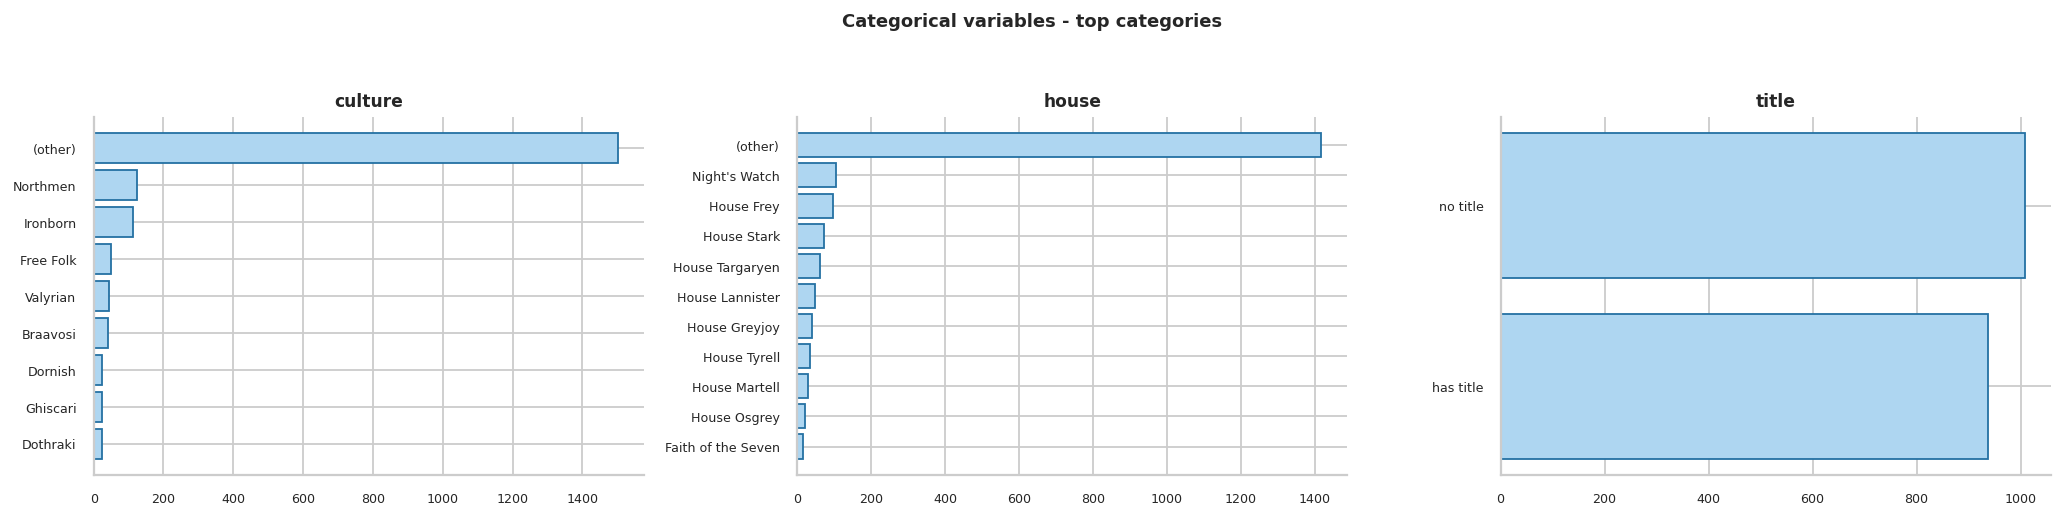

In [ ]:
# Categorical variables - most frequent categories
def group_top(s, n):
    """Keep the n most frequent categories, label the rest as '(other)' and
    missing values as '(missing)'. Used only for plotting."""
    top = s.value_counts().head(n).index
    return s.where(s.isin(top), other='(other)').fillna('(missing)')

cats = {
    'culture': group_top(df.culture, 8),
    'house':   group_top(df.house, 10),
    'title':   df.title.notna().map({True: 'has title', False: 'no title'}),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (name, s) in zip(axes, cats.items()):
    vc = s.value_counts()
    ax.barh(vc.index[::-1].astype(str), vc.values[::-1], color='#AED6F1', edgecolor='#2471A3')
    ax.set_title(name, fontsize=9.5, fontweight='bold')
    ax.tick_params(labelsize=7)

plt.suptitle('Categorical variables - top categories', fontsize=10, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig5_categorical.png', bbox_inches='tight')
plt.show()

### 1.6 Correlation structure — numeric/binary (point-biserial) and categorical (Cramér's V)
All numeric and binary variables are included (not only the continuous ones).

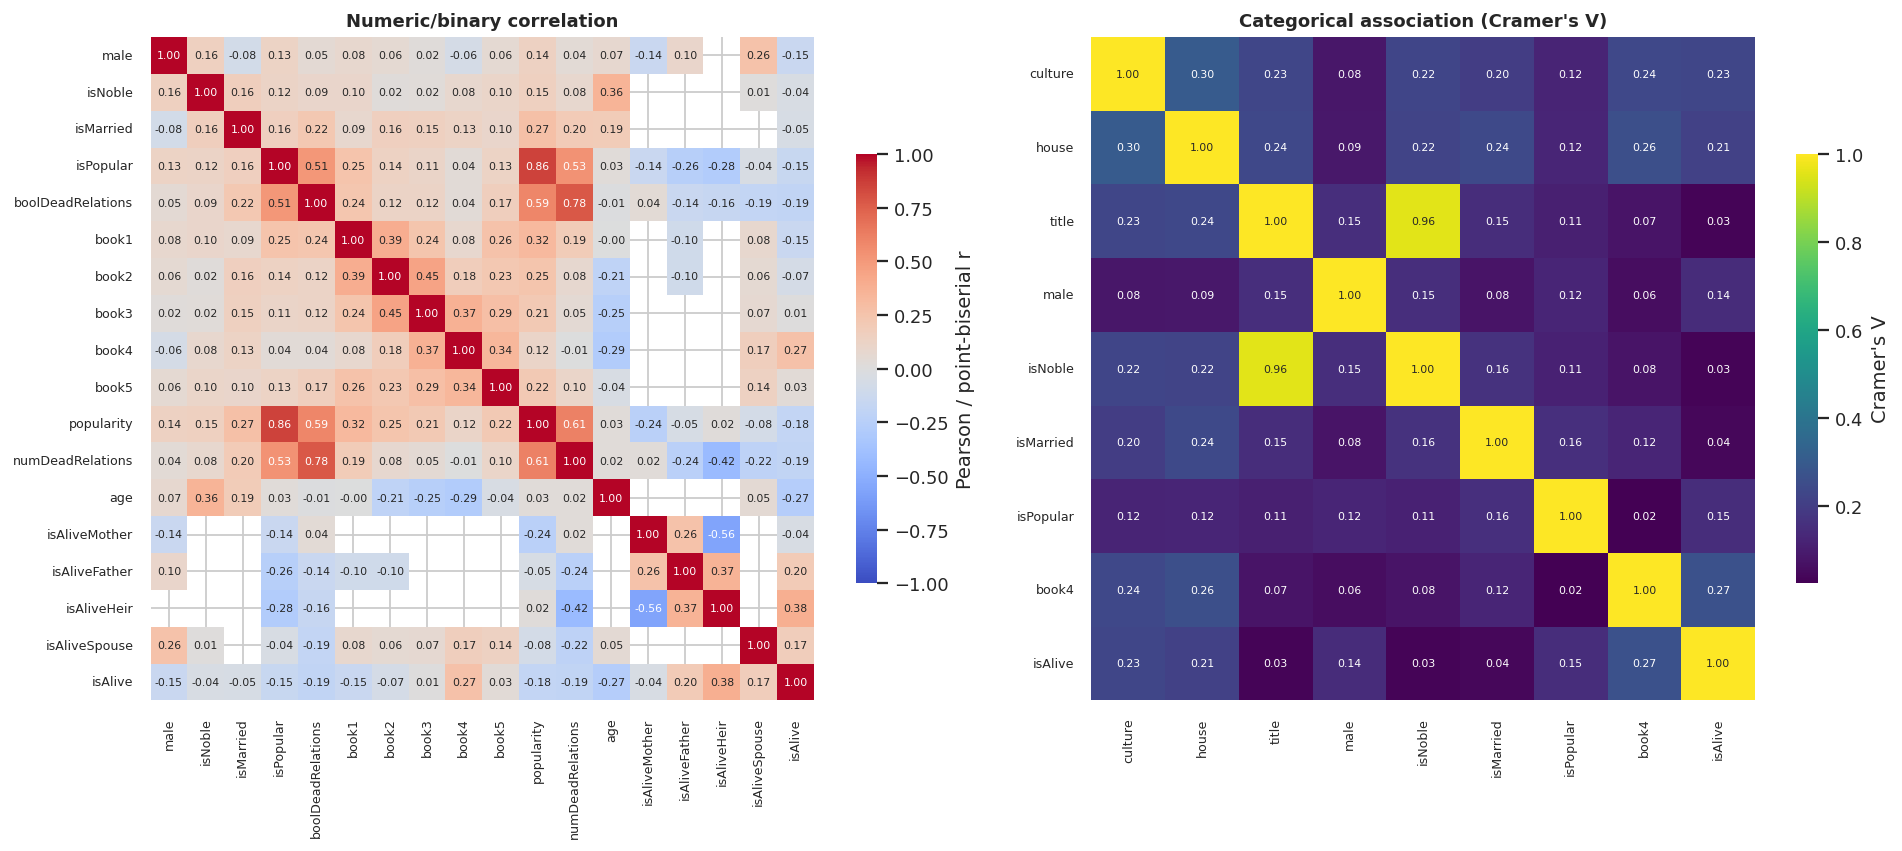

Note (left heatmap): blank cells = NaN. The isAlive* columns are 86-99% missing, so two of
them rarely share non-null rows and their correlation is undefined. The values that do appear
among them (e.g. isAliveMother~isAliveHeir = -0.56) rest on very few rows and are unreliable,
which is why these variables are dropped from the model.


In [ ]:
# Figure 6 - correlation structure: numeric/binary (left) and categorical (right)
# A clean copy where the impossible ages are set to NaN, only for these statistics
tmp = df.copy()
tmp.loc[(tmp.age < 0) | (tmp.age > 120), 'age'] = np.nan

numeric_binary = ['male', 'isNoble', 'isMarried', 'isPopular', 'boolDeadRelations',
                  'book1', 'book2', 'book3', 'book4', 'book5',
                  'popularity', 'numDeadRelations', 'age',
                  'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse']

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# (a) Pearson / point-biserial correlation between numeric and binary variables
sns.heatmap(tmp[numeric_binary + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, ax=axes[0], annot_kws={'size': 6},
            cbar_kws={'shrink': 0.6, 'label': 'Pearson / point-biserial r'})
axes[0].set_title('Numeric/binary correlation', fontsize=10, fontweight='bold')
axes[0].tick_params(labelsize=7)

# (b) Cramer's V association between the categorical variables
categorical = {
    'culture':   group_top(df.culture, 8),
    'house':     group_top(df.house, 10),
    'title':     df.title.notna().astype(int),
    'male':      df.male,
    'isNoble':   df.isNoble,
    'isMarried': df.isMarried,
    'isPopular': df.isPopular,
    'book4':     df.book4,
    'isAlive':   df[TARGET],
}
cat_df = pd.DataFrame(categorical)
cols = list(cat_df.columns)
M = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
for i in cols:
    for j in cols:
        if i != j:
            M.loc[i, j] = cramers_v(cat_df[i].astype(str), cat_df[j].astype(str))

sns.heatmap(M.astype(float), annot=True, fmt='.2f', cmap='viridis', square=True, ax=axes[1],
            annot_kws={'size': 6}, cbar_kws={'shrink': 0.6, 'label': "Cramer's V"})
axes[1].set_title("Categorical association (Cramer's V)", fontsize=10, fontweight='bold')
axes[1].tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig6_corr_structure.png', bbox_inches='tight')
plt.show()

print('Note (left heatmap): blank cells = NaN. The isAlive* columns are 86-99% missing, so two of')
print('them rarely share non-null rows and their correlation is undefined. The values that do appear')
print('among them (e.g. isAliveMother~isAliveHeir = -0.56) rest on very few rows and are unreliable,')
print('which is why these variables are dropped from the model.')

### 1.7 Association with the target — numeric and categorical, ranked separately

Numeric/binary |r| with isAlive:
age                  0.271
book4                0.269
boolDeadRelations    0.194
numDeadRelations     0.192
popularity           0.183
isPopular            0.154
book1                0.147
male                 0.147
book2                0.067
isMarried            0.050
isNoble              0.042
book5                0.033
book3                0.007

Categorical Cramer's V with isAlive:
culture    0.228
house      0.213
mother     0.137
father     0.131
heir       0.125
spouse     0.043
title      0.033


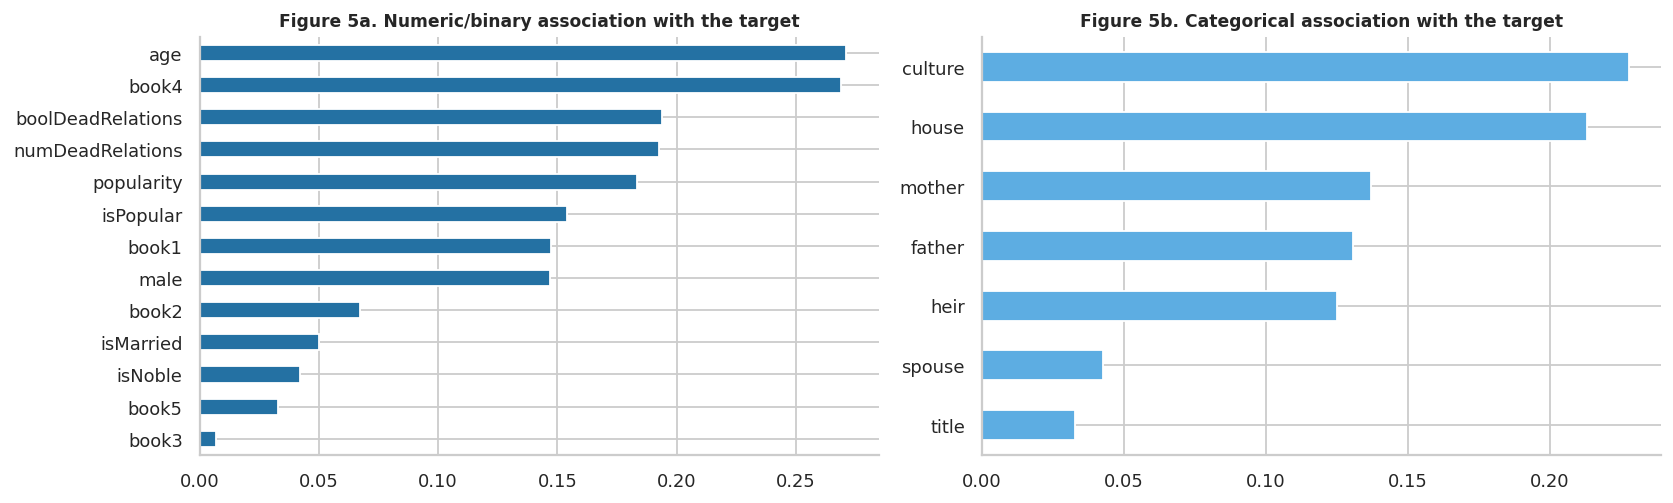

In [ ]:
# Figure 5 - how strongly each variable is associated with the target
# Numeric/binary: absolute Spearman correlation
numeric_cols = ['male', 'isNoble', 'isMarried', 'isPopular', 'boolDeadRelations',
                'book1', 'book2', 'book3', 'book4', 'book5',
                'popularity', 'numDeadRelations', 'age']
num_assoc = tmp[numeric_cols].corrwith(tmp[TARGET]).abs().sort_values(ascending=False)

# Categorical: Cramer's V (presence used for the high-missing identity columns)
categorical = {
    'culture': group_top(df.culture, 8),
    'house':   group_top(df.house, 10),
    'title':   df.title.notna().astype(int),
    'mother':  df.mother.notna().astype(int),
    'father':  df.father.notna().astype(int),
    'heir':    df.heir.notna().astype(int),
    'spouse':  df.spouse.notna().astype(int),
}
cat_assoc = pd.Series({k: cramers_v(v.astype(str), df[TARGET].astype(str))
                       for k, v in categorical.items()}).sort_values(ascending=False)

print('Numeric/binary |r| with isAlive:')
print(num_assoc.round(3).to_string())
print("\nCategorical Cramer's V with isAlive:")
print(cat_assoc.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
num_assoc.iloc[::-1].plot.barh(ax=axes[0], color='#2471A3')
axes[0].set_title('Figure 5a. Numeric/binary association with the target', fontsize=9.5, fontweight='bold')
cat_assoc.iloc[::-1].plot.barh(ax=axes[1], color='#5DADE2')
axes[1].set_title('Figure 5b. Categorical association with the target', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig7_target_assoc.png', bbox_inches='tight')
plt.show()

### 1.8 Gender & nobility vs survival

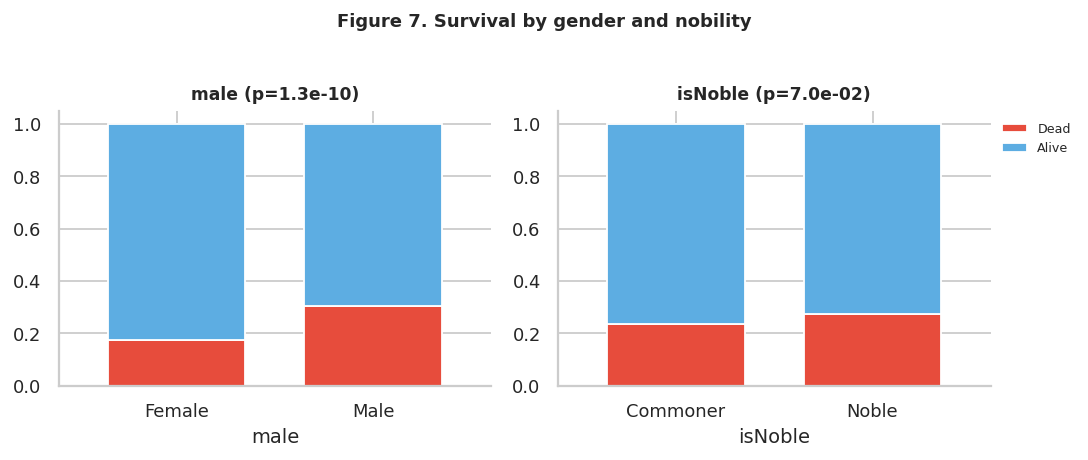

Women 82.7% vs men 69.5% (p=1.3e-10, significant). Nobility 72.6% vs 76.3% (p=0.07, not significant).


In [ ]:
# Figure 7 - survival by sex and by nobility, with a chi-square significance test
def chi2_pvalue(col):
    """p-value of the chi-square test between a column and the target."""
    return chi2_contingency(pd.crosstab(df[col], df[TARGET]))[1]

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, col, labels in zip(axes, ['male', 'isNoble'], [('Female', 'Male'), ('Commoner', 'Noble')]):
    proportions = pd.crosstab(df[col], df[TARGET], normalize='index')
    proportions.plot.bar(stacked=True, ax=ax, color=['#E74C3C', '#5DADE2'], legend=False, width=0.7)
    ax.set_xticklabels(labels, rotation=0)
    ax.set_title(f'{col} (p={chi2_pvalue(col):.1e})', fontsize=9.5, fontweight='bold')

axes[1].legend(['Dead', 'Alive'], fontsize=7, frameon=False, bbox_to_anchor=(1, 1))
plt.suptitle('Figure 7. Survival by gender and nobility', fontsize=10, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig8_gender_nobility.png', bbox_inches='tight')
plt.show()

print('Women 82.7% vs men 69.5% (p=1.3e-10, significant). Nobility 72.6% vs 76.3% (p=0.07, not significant).')

### 1.9 House allegiance vs survival

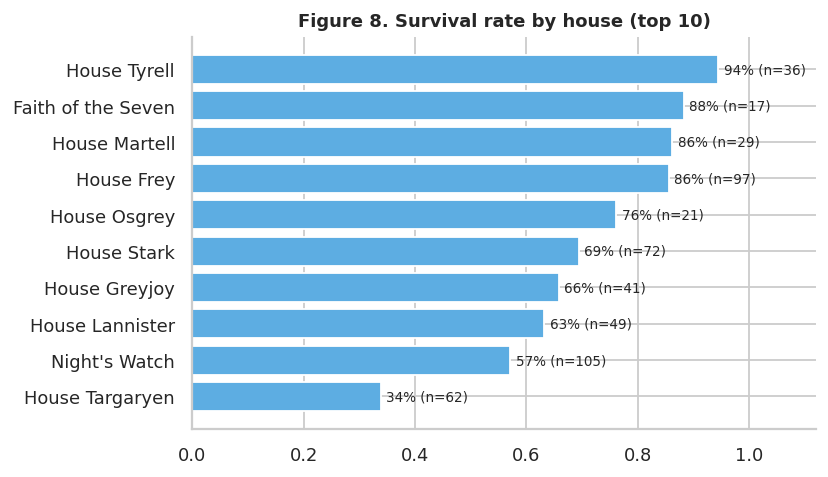

In [ ]:
# Figure 8 - survival rate of the ten largest houses
top_houses = df.house.value_counts().head(10).index
house_rate = (df[df.house.isin(top_houses)]
              .groupby('house')[TARGET].agg(['mean', 'size'])
              .sort_values('mean'))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.barh(house_rate.index, house_rate['mean'], color='#5DADE2', edgecolor='white')
for bar, mean, n in zip(bars, house_rate['mean'], house_rate['size']):
    ax.text(mean + 0.01, bar.get_y() + bar.get_height() / 2, f'{mean * 100:.0f}% (n={n})',
            va='center', fontsize=7.5)

ax.set_xlim(0, 1.12)
ax.set_title('Figure 8. Survival rate by house (top 10)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig9_house.png', bbox_inches='tight')
plt.show()

## 2. Feature selection 

### 2.1 `isMarried` is identical to "has a spouse" 

In [ ]:
# Feature-selection check 1: is isMarried the same as "having a spouse"?
table = pd.crosstab(df.isMarried, df.spouse.notna())
agreement = (df.isMarried == df.spouse.notna().astype(int)).mean()

print(table.to_string())
print(f'\nAgreement isMarried == has_spouse: {agreement:.3f}')
print('=> isMarried already encodes spouse presence, so we keep isMarried (0% missing) and drop the spouse name.')

spouse     False  True 
isMarried              
0           1670      0
1              0    276

Agreement isMarried == has_spouse: 1.000
=> isMarried already encodes spouse presence, so we keep isMarried (0% missing) and drop the spouse name.


### 2.2 Presence flags are proxies of "documented character" (popularity / dead relatives)

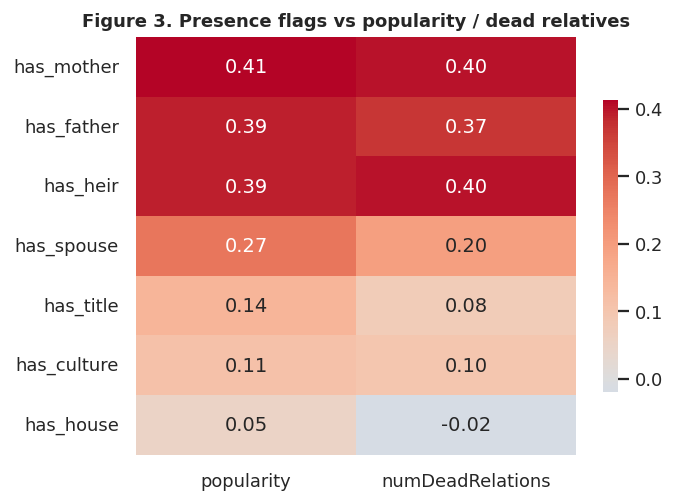

has_mother / has_father / has_heir correlate about 0.4 with popularity and dead relatives,
so they mostly repeat that information and are dropped.
has_title correlates only about 0.14, so it is an independent status signal and is kept.


In [ ]:
# Figure 3 - are the presence flags just a proxy for "famous character"?
# Build the has_* flags and correlate them with popularity and dead relatives
flags = {f'has_{c}': df[c].notna().astype(int)
         for c in ['mother', 'father', 'heir', 'spouse', 'title', 'culture', 'house']}
flags_df = pd.DataFrame(flags)
reference = df[['popularity', 'numDeadRelations']]

corr_flags = pd.concat([flags_df, reference], axis=1).corr().loc[list(flags), ['popularity', 'numDeadRelations']]

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(corr_flags, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink': 0.7})
ax.set_title('Figure 3. Presence flags vs popularity / dead relatives', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig10_flag_redundancy.png', bbox_inches='tight')
plt.show()

print('has_mother / has_father / has_heir correlate about 0.4 with popularity and dead relatives,')
print('so they mostly repeat that information and are dropped.')
print('has_title correlates only about 0.14, so it is an independent status signal and is kept.')

### 2.3 `age`: real but unrecoverable signal

Among the 431 characters with a valid age:
  corr(age, isAlive)        = -0.271
  corr(popularity, isAlive) = -0.041
  -> age carries its own signal, not explained by popularity.

Of the 1515 rows missing age, only 0 have a valid dateOfBirth
=> age cannot be reconstructed (78% missing) -> dropped, with no fabricated imputation.


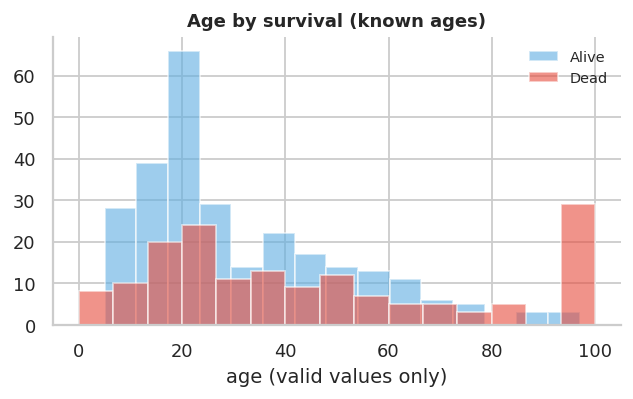

In [ ]:
# Feature-selection check 2: does age carry useful, recoverable information?
known_age = df[df.age.between(0, 120)]
print(f'Among the {len(known_age)} characters with a valid age:')
print(f'  corr(age, isAlive)        = {known_age.age.corr(known_age[TARGET]):.3f}')
print(f'  corr(popularity, isAlive) = {known_age.popularity.corr(known_age[TARGET]):.3f}')
print('  -> age carries its own signal, not explained by popularity.')

# but can we recover the missing ages from the date of birth?
missing_age = ~df.age.between(0, 120)
recoverable = (missing_age & df.dateOfBirth.between(0, 1000)).sum()
print(f'\nOf the {missing_age.sum()} rows missing age, only {recoverable} have a valid dateOfBirth')
print('=> age cannot be reconstructed (78% missing) -> dropped, with no fabricated imputation.')

fig, ax = plt.subplots(figsize=(5, 3.2))
for value, color, label in [(1, '#5DADE2', 'Alive'), (0, '#E74C3C', 'Dead')]:
    ax.hist(known_age[known_age[TARGET] == value]['age'], bins=15, alpha=0.6, color=color, label=label)
ax.set_xlabel('age (valid values only)')
ax.legend(frameon=False, fontsize=8)
ax.set_title('Age by survival (known ages)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig11_age_signal.png', bbox_inches='tight')
plt.show()

### 2.4 Effective sample size of high-missing variables (reliability of their correlation)

In [ ]:
# Feature-selection check 3: how much real data backs each high-missing column?
cols = ['age', 'spouse', 'title', 'culture', 'mother', 'father', 'heir', 'isAliveHeir']
effective = pd.DataFrame({'non_null': [df[c].notna().sum() for c in cols]}, index=cols)
effective['pct'] = (effective['non_null'] / len(df) * 100).round(1)
print(effective.to_string())
print('=> mother / father / heir and the isAlive* flags rest on about 20-26 rows,')
print('   so their correlations are unreliable and they are dropped.')

             non_null   pct
age               433  22.3
spouse            276  14.2
title             938  48.2
culture           677  34.8
mother             21   1.1
father             26   1.3
heir               23   1.2
isAliveHeir        23   1.2
=> mother / father / heir and the isAlive* flags rest on about 20-26 rows,
   so their correlations are unreliable and they are dropped.


## 3. Data transformation
**Kept:** `male, popularity, numDeadRelations, book1-5` (book presence across the story timeline), `isMarried` and `has_title` (status markers that not every character holds) + grouped one-hot of `culture` (top-8) and `house` (top-10). **Dropped:** the `has_mother/father/heir` flags (shown to be popularity proxies, Fig. 10) and the relative names, `age` (78% missing, unrecoverable), `isNoble` (weak), `isAlive*` (unreliable, ~20 rows), and all leakage/IDs.

In [ ]:
# ============================================================================
# Final transformation: build the feature matrix X and the target y
# ============================================================================
def normalize_culture(x):
    """Unify the different spellings of each culture into a single label."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    mapping = {
        'free folk': 'Free Folk', 'wildling': 'Free Folk', 'wildlings': 'Free Folk', 'thenn': 'Free Folk',
        'dornish': 'Dornish', 'dornishmen': 'Dornish', 'dorne': 'Dornish',
        'ironborn': 'Ironborn', 'ironmen': 'Ironborn',
        'northmen': 'Northmen', 'northern': 'Northmen',
        'valyrian': 'Valyrian', 'braavosi': 'Braavosi', 'braavos': 'Braavosi',
        'reach': 'Reach', 'reachmen': 'Reach', 'the reach': 'Reach',
        'rivermen': 'Rivermen', 'riverlands': 'Rivermen',
        'westeros': 'Westeros', 'westerman': 'Westerlands', 'westermen': 'Westerlands', 'westerlands': 'Westerlands',
        'andal': 'Andals', 'andals': 'Andals',
        'ghiscari': 'Ghiscari', 'meereen': 'Ghiscari',
        'dothraki': 'Dothraki',
        'valemen': 'Vale', 'vale': 'Vale', 'vale mountain clans': 'Vale',
        'stormlands': 'Stormlands', 'stormlander': 'Stormlands',
        'crownlands': 'Crownlands',
        'summer islands': 'Summer Isles', 'summer isles': 'Summer Isles',
        'lysene': 'Lyseni', 'lyseni': 'Lyseni',
    }
    return mapping.get(s, s.title())


def build_features(d):
    d = d.copy()

    # culture: normalise spellings, keep the top 8 and one-hot encode (missing -> 'Unknown')
    d['culture_g'] = d.culture.apply(normalize_culture)
    top_cultures = d['culture_g'].value_counts().head(8).index
    d['culture_g'] = np.where(d['culture_g'].isin(top_cultures), d['culture_g'],
                              np.where(d['culture_g'].isna(), 'Unknown', 'Other'))
    culture_ohe = pd.get_dummies(d['culture_g'], prefix='cult')

    # has_title: 1 if a title is recorded, 0 if not (presence flag, no value invented)
    d['has_title'] = d.title.notna().astype(int)

    # house: keep the top 10 and one-hot encode (missing -> 'NoHouse')
    top_houses = d.house.value_counts().head(10).index
    house_grouped = np.where(d.house.isin(top_houses), d.house,
                             np.where(d.house.isna(), 'NoHouse', 'OtherHouse'))
    house_ohe = pd.get_dummies(pd.Series(house_grouped, index=d.index), prefix='house')

    # numeric and binary variables we keep as they are
    keep = ['male', 'popularity', 'numDeadRelations',
            'book1', 'book2', 'book3', 'book4', 'book5',
            'isMarried', 'has_title']

    X = pd.concat([d[keep], culture_ohe, house_ohe], axis=1)
    X.columns = [str(c).replace(' ', '_') for c in X.columns]
    return X, d[TARGET].astype(int)


X, y = build_features(df)
print('Engineered features:', X.shape[1])
X.head()

Engineered features: 32


,male,popularity,numDeadRelations,book1,book2,book3,book4,book5,isMarried,has_title,...,house_House_Greyjoy,house_House_Lannister,house_House_Martell,house_House_Osgrey,house_House_Stark,house_House_Targaryen,house_House_Tyrell,house_Night's_Watch,house_NoHouse,house_OtherHouse
0,1,0.605351,11,0,0,0,0,0,0,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0.896321,1,1,1,1,1,1,1,1,...,False,False,False,False,False,False,False,False,False,False
2,1,0.267559,0,0,0,0,1,0,0,1,...,False,False,False,False,False,False,False,False,False,True
3,0,0.183946,0,0,0,0,0,0,1,1,...,False,False,False,False,False,False,False,False,False,True
4,0,0.043478,0,0,0,0,1,0,1,1,...,False,False,False,False,False,False,False,False,False,True


### 3.1 Multicollinearity of the final feature set
Before modelling we check correlations **among the engineered features**. Tree ensembles tolerate multicollinearity, but it splits importance between correlated features and adds redundant dimensions for KNN/SVM, so it must be documented.

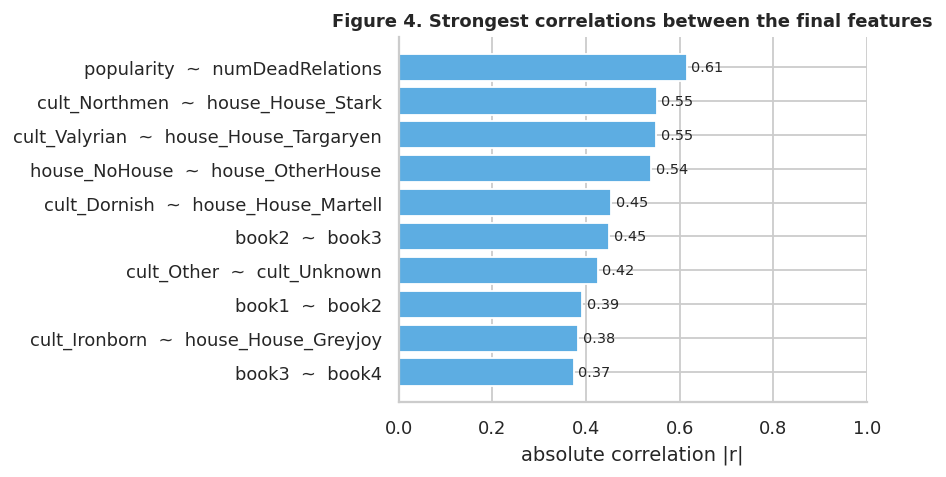

Feature pairs with |r| > 0.30 (redundancy):
popularity      numDeadRelations         0.61
cult_Northmen   house_House_Stark        0.55
cult_Valyrian   house_House_Targaryen    0.55
house_NoHouse   house_OtherHouse         0.54
cult_Dornish    house_House_Martell      0.45
book2           book3                    0.45
cult_Other      cult_Unknown             0.42
book1           book2                    0.39
cult_Ironborn   house_House_Greyjoy      0.38
book3           book4                    0.37
cult_Northmen   cult_Unknown             0.37
cult_Ironborn   cult_Unknown             0.35
book4           book5                    0.34
popularity      book1                    0.32
cult_Free_Folk  house_NoHouse            0.32


In [ ]:
# Figure 4 - strongest correlations between the final features (multicollinearity check)
corr_X = X.corr()

# take the upper triangle, sort the pairs by absolute correlation, keep the top 10
upper = corr_X.abs().where(np.triu(np.ones(corr_X.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
top_pairs = pairs.head(10)
labels = [f'{a}  ~  {b}' for a, b in top_pairs.index]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(labels[::-1], top_pairs.values[::-1], color='#5DADE2', edgecolor='white')
for i, v in enumerate(top_pairs.values[::-1]):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel('absolute correlation |r|')
ax.set_title('Figure 4. Strongest correlations between the final features', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig11b_multicollinearity.png', bbox_inches='tight')
plt.show()

print('Feature pairs with |r| > 0.30 (redundancy):')
print(pairs[pairs > 0.30].round(2).to_string())

## 4. Model building — five algorithms, five hyper-parameter sets each
Naive Bayes compares **GaussianNB and BernoulliNB** (no NB type is ideal for mixed binary+continuous
data; the best is kept). KNN/SVM are scaled; trees are not.

In [ ]:
# ============================================================================
# Model building: 5 algorithms, 5 configurations each, selected by F1-macro
# ============================================================================
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train', X_tr.shape, ' Test', X_te.shape, ' Dead in test', int((y_te == 0).sum()))

cv = StratifiedKFold(5, shuffle=True, random_state=RS)
SCORING = 'f1_macro'


def scaled(estimator):
    """Wrap an estimator in a pipeline that standardises the features first
    (needed by distance/margin based models such as KNN and SVM)."""
    return Pipeline([('sc', StandardScaler()), ('m', estimator)])


def plain(estimator):
    """Pipeline without scaling (trees do not need it)."""
    return Pipeline([('m', estimator)])


# Five configurations per algorithm
zoo = {
    'KNN': [
        (f'k={k},{w}', scaled(KNeighborsClassifier(n_neighbors=k, weights=w)))
        for k, w in [(5, 'uniform'), (5, 'distance'), (11, 'distance'), (15, 'distance'), (21, 'distance')]
    ],
    'DecisionTree': [
        (f'd={d},leaf={l}', plain(DecisionTreeClassifier(max_depth=d, min_samples_leaf=l,
                                                          class_weight='balanced', random_state=RS)))
        for d, l in [(3, 1), (5, 5), (8, 5), (None, 5), (None, 10)]
    ],
    # Naive Bayes: compare the Gaussian variant with the Bernoulli one (better for binary data)
    'Bayesian': [
        ('GaussianNB vs=1e-9', scaled(GaussianNB(var_smoothing=1e-9))),
        ('GaussianNB vs=1e-6', scaled(GaussianNB(var_smoothing=1e-6))),
        ('GaussianNB vs=1e-3', scaled(GaussianNB(var_smoothing=1e-3))),
        ('BernoulliNB a=0.5',  plain(BernoulliNB(alpha=0.5))),
        ('BernoulliNB a=1.0',  plain(BernoulliNB(alpha=1.0))),
    ],
    'SVM': [
        (f'C={c},{k}', scaled(SVC(C=c, kernel=k, gamma='scale', class_weight='balanced',
                                  probability=False, random_state=RS)))
        for c, k in [(0.1, 'rbf'), (1, 'rbf'), (10, 'rbf'), (1, 'linear'), (5, 'rbf')]
    ],
    'RandomForest': [
        (f'n={n},d={d},leaf={l}', plain(RandomForestClassifier(n_estimators=n, max_depth=d, min_samples_leaf=l,
                                                               class_weight='balanced', random_state=RS, n_jobs=1)))
        for n, d, l in [(300, None, 1), (300, 12, 1), (500, 12, 3), (300, 8, 3), (500, None, 3)]
    ],
}


def proba_or_score(model, X_):
    """Probability of the positive class, or the decision function for SVM."""
    return model.predict_proba(X_)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_)


best_models = {}
results = []
all_cv = []

for family, configs in zoo.items():
    scored = []
    # cross-validate every configuration of this algorithm
    for name, pipe in configs:
        mean_cv = cross_val_score(pipe, X_tr, y_tr, scoring=SCORING, cv=cv, n_jobs=1).mean()
        scored.append((name, pipe, mean_cv))
        all_cv.append({'algorithm': family, 'configuration': name, 'cv_f1_macro': round(mean_cv, 3)})

    # keep the best configuration, refit it on the whole training set and test it
    name, pipe, mean_cv = max(scored, key=lambda t: t[2])
    pipe = clone(pipe)
    pipe.fit(X_tr, y_tr)
    best_models[family] = pipe

    y_pred = pipe.predict(X_te)
    results.append({
        'model': family, 'best_config': name,
        'cv_f1macro': round(mean_cv, 3),
        'accuracy':   round(accuracy_score(y_te, y_pred), 3),
        'bal_acc':    round(balanced_accuracy_score(y_te, y_pred), 3),
        'f1_macro':   round(f1_score(y_te, y_pred, average='macro'), 3),
        'prec_dead':  round(precision_score(y_te, y_pred, pos_label=0), 3),
        'rec_dead':   round(recall_score(y_te, y_pred, pos_label=0), 3),
        'f1_dead':    round(f1_score(y_te, y_pred, pos_label=0), 3),
        'rec_alive':  round(recall_score(y_te, y_pred, pos_label=1), 3),
        'roc_auc':    round(roc_auc_score(y_te, proba_or_score(pipe, X_te)), 3),
    })
    print(f'{family:13s} best={name:22s} cvF1={mean_cv:.3f} testF1={results[-1]["f1_macro"]}')

results_df = pd.DataFrame(results).sort_values('f1_macro', ascending=False).reset_index(drop=True)
results_df.to_csv(FIGURES_DIR / 'table_models.csv', index=False)

all_cv_df = pd.DataFrame(all_cv)
all_cv_df.to_csv(FIGURES_DIR / 'table_all_configs.csv', index=False)

results_df

Train (1556, 32)  Test (390, 32)  Dead in test 99


KNN           best=k=5,distance           cvF1=0.656 testF1=0.689
DecisionTree  best=d=None,leaf=5          cvF1=0.673 testF1=0.67


Bayesian      best=BernoulliNB a=0.5      cvF1=0.638 testF1=0.593


SVM           best=C=5,rbf                cvF1=0.689 testF1=0.674


RandomForest  best=n=300,d=12,leaf=1      cvF1=0.730 testF1=0.729


,model,best_config,cv_f1macro,accuracy,bal_acc,f1_macro,prec_dead,rec_dead,f1_dead,rec_alive,roc_auc
0,RandomForest,"n=300,d=12,leaf=1",0.730,0.792,0.731,0.729,0.588,0.606,0.597,0.856,0.839
1,KNN,"k=5,distance",0.656,0.782,0.677,0.689,0.590,0.465,0.520,0.890,0.793
2,SVM,"C=5,rbf",0.689,0.715,0.713,0.674,0.461,0.707,0.558,0.718,0.780
3,DecisionTree,"d=None,leaf=5",0.673,0.718,0.701,0.670,0.462,0.667,0.545,0.735,0.744
4,Bayesian,BernoulliNB a=0.5,0.638,0.746,0.587,0.593,0.500,0.263,0.344,0.911,0.728


### 4.1 The five configurations per algorithm (CV F1-macro)

In [ ]:
# Every hyper-parameter configuration tried, with its cross-validated F1-macro
from IPython.display import display
display(all_cv_df)

,algorithm,configuration,cv_f1_macro
0,KNN,"k=5,uniform",0.655
1,KNN,"k=5,distance",0.656
2,KNN,"k=11,distance",0.648
3,KNN,"k=15,distance",0.652
4,KNN,"k=21,distance",0.636
5,DecisionTree,"d=3,leaf=1",0.642
6,DecisionTree,"d=5,leaf=5",0.662
7,DecisionTree,"d=8,leaf=5",0.671
8,DecisionTree,"d=None,leaf=5",0.673
9,DecisionTree,"d=None,leaf=10",0.666


## 5. Evaluation and per-model visualisation

### 5.1 Confusion matrices and ROC curves (all models)

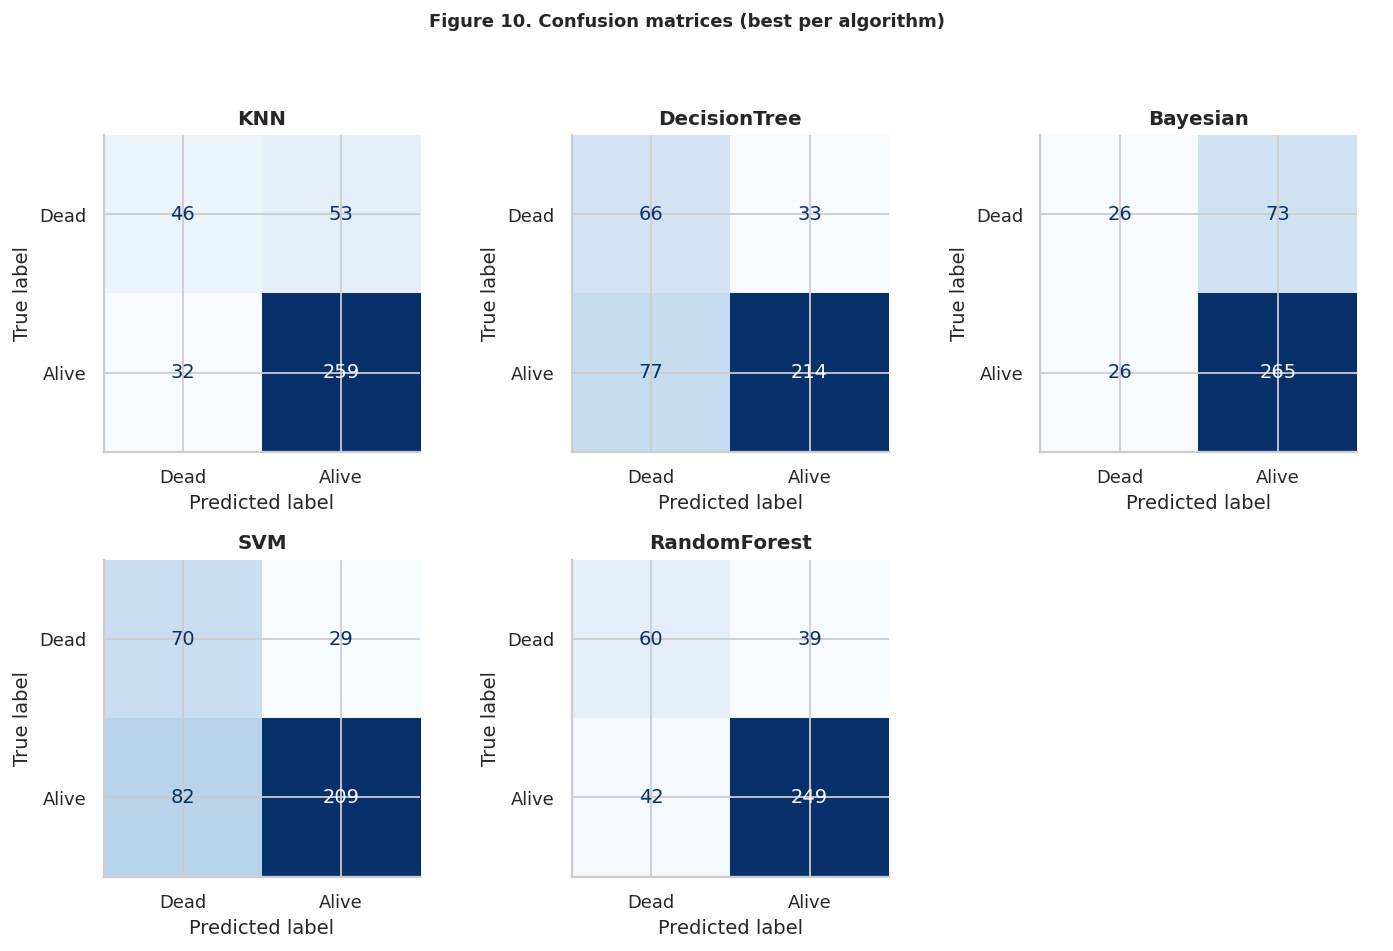

In [ ]:
# Figure 10 - confusion matrix of the best model of each algorithm
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
axes = axes.flatten()
for ax, family in zip(axes, zoo):
    cm = confusion_matrix(y_te, best_models[family].predict(X_te))
    ConfusionMatrixDisplay(cm, display_labels=['Dead', 'Alive']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(family, fontsize=11, fontweight='bold')
axes[-1].axis('off')                       # hide the empty 6th panel

plt.suptitle('Figure 10. Confusion matrices (best per algorithm)', fontsize=10, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig12_confmats.png', bbox_inches='tight')
plt.show()

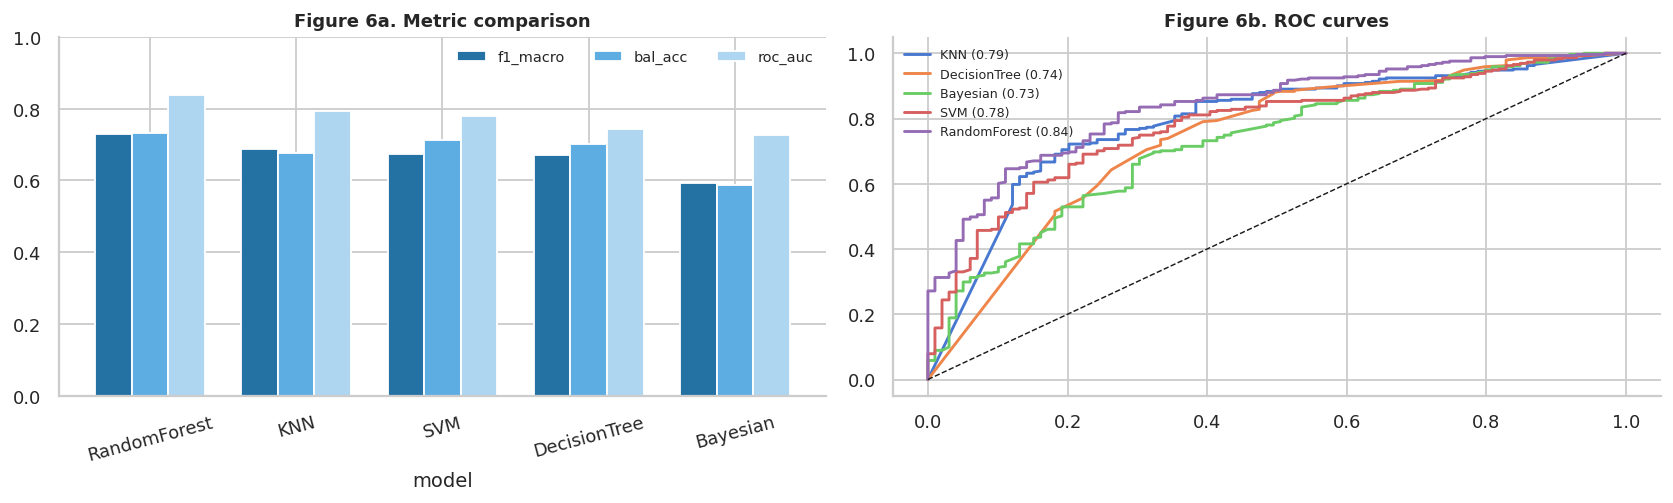

Best: RandomForest


In [ ]:
# Figure 6 - metric comparison (left) and ROC curves (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# left: main metrics per model
results_df.set_index('model')[['f1_macro', 'bal_acc', 'roc_auc']].plot.bar(
    ax=axes[0], width=0.75, color=['#2471A3', '#5DADE2', '#AED6F1'])
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(fontsize=8, frameon=False, ncol=3)
axes[0].set_title('Figure 6a. Metric comparison', fontsize=10, fontweight='bold')

# right: ROC curve of each model
for family in zoo:
    fpr, tpr, _ = roc_curve(y_te, proba_or_score(best_models[family], X_te))
    auc = roc_auc_score(y_te, proba_or_score(best_models[family], X_te))
    axes[1].plot(fpr, tpr, lw=1.6, label=f'{family} ({auc:.2f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].legend(fontsize=7, frameon=False)
axes[1].set_title('Figure 6b. ROC curves', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig13_comparison.png', bbox_inches='tight')
plt.show()

best_name = results_df.iloc[0]['model']
best = best_models[best_name]
print('Best:', best_name)

### 5.2 SVM — decision boundary on a 2-D PCA projection

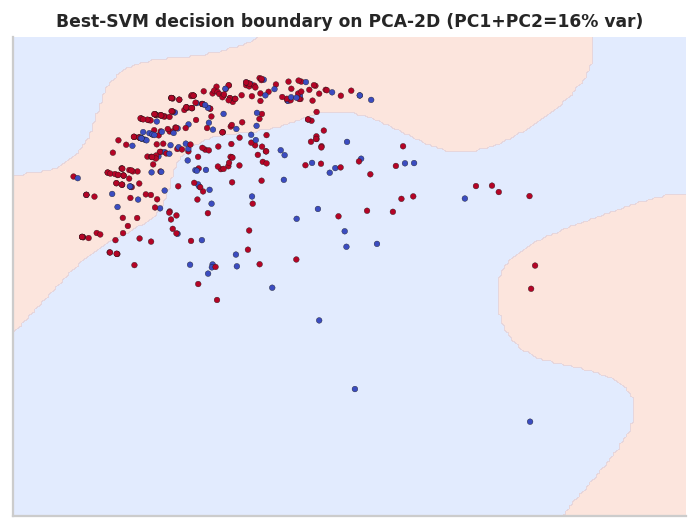

PCA explains little variance here, so this 2-D view is only a visual aid; the metrics come
from the full model.


In [ ]:
# SVM decision boundary on a 2-D PCA projection (visual intuition only)
scaler_2d = StandardScaler().fit(X_tr)
pca = PCA(2, random_state=RS).fit(scaler_2d.transform(X_tr))
Z_tr = pca.transform(scaler_2d.transform(X_tr))
Z_te = pca.transform(scaler_2d.transform(X_te))

# retrain an SVM with the BEST SVM hyper-parameters on the 2-D data
svm_params = best_models['SVM'].named_steps['m']
svm_2d = SVC(C=svm_params.C, kernel=svm_params.kernel, gamma=svm_params.gamma,
            class_weight='balanced').fit(Z_tr, y_tr)

xx, yy = np.meshgrid(np.linspace(Z_tr[:, 0].min() - 1, Z_tr[:, 0].max() + 1, 200),
                     np.linspace(Z_tr[:, 1].min() - 1, Z_tr[:, 1].max() + 1, 200))
regions = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.contourf(xx, yy, regions, alpha=0.25, cmap='coolwarm', levels=1)
ax.scatter(Z_te[:, 0], Z_te[:, 1], c=y_te, cmap='coolwarm', s=10, edgecolor='k', linewidth=0.2)
ax.set_title(f'Best-SVM decision boundary on PCA-2D (PC1+PC2={pca.explained_variance_ratio_.sum() * 100:.0f}% var)',
             fontsize=9.5, fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig14_svm_pca.png', bbox_inches='tight')
plt.show()

print('PCA explains little variance here, so this 2-D view is only a visual aid; the metrics come')
print('from the full model.')

### 5.3 KNN — class clusters on the PCA projection

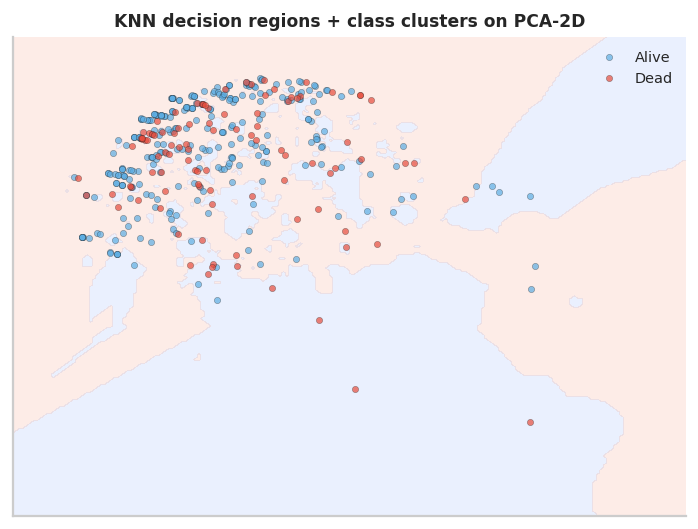

The two classes overlap heavily in 2-D, which explains the limited separability of distance models.


In [ ]:
# KNN decision regions and class clusters on the same PCA projection
knn_params = best_models['KNN'].named_steps['m']
knn_2d = KNeighborsClassifier(n_neighbors=knn_params.n_neighbors, weights=knn_params.weights).fit(Z_tr, y_tr)
regions = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.contourf(xx, yy, regions, alpha=0.18, cmap='coolwarm', levels=1)
for value, color, label in [(1, '#5DADE2', 'Alive'), (0, '#E74C3C', 'Dead')]:
    ax.scatter(Z_te[y_te == value, 0], Z_te[y_te == value, 1], s=12, c=color, label=label,
               edgecolor='k', linewidth=0.2, alpha=0.7)
ax.legend(frameon=False, fontsize=8)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title('KNN decision regions + class clusters on PCA-2D', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig15_knn_clusters.png', bbox_inches='tight')
plt.show()

print('The two classes overlap heavily in 2-D, which explains the limited separability of distance models.')

### 5.4 Decision Tree — readable top levels (how the decisions are made)

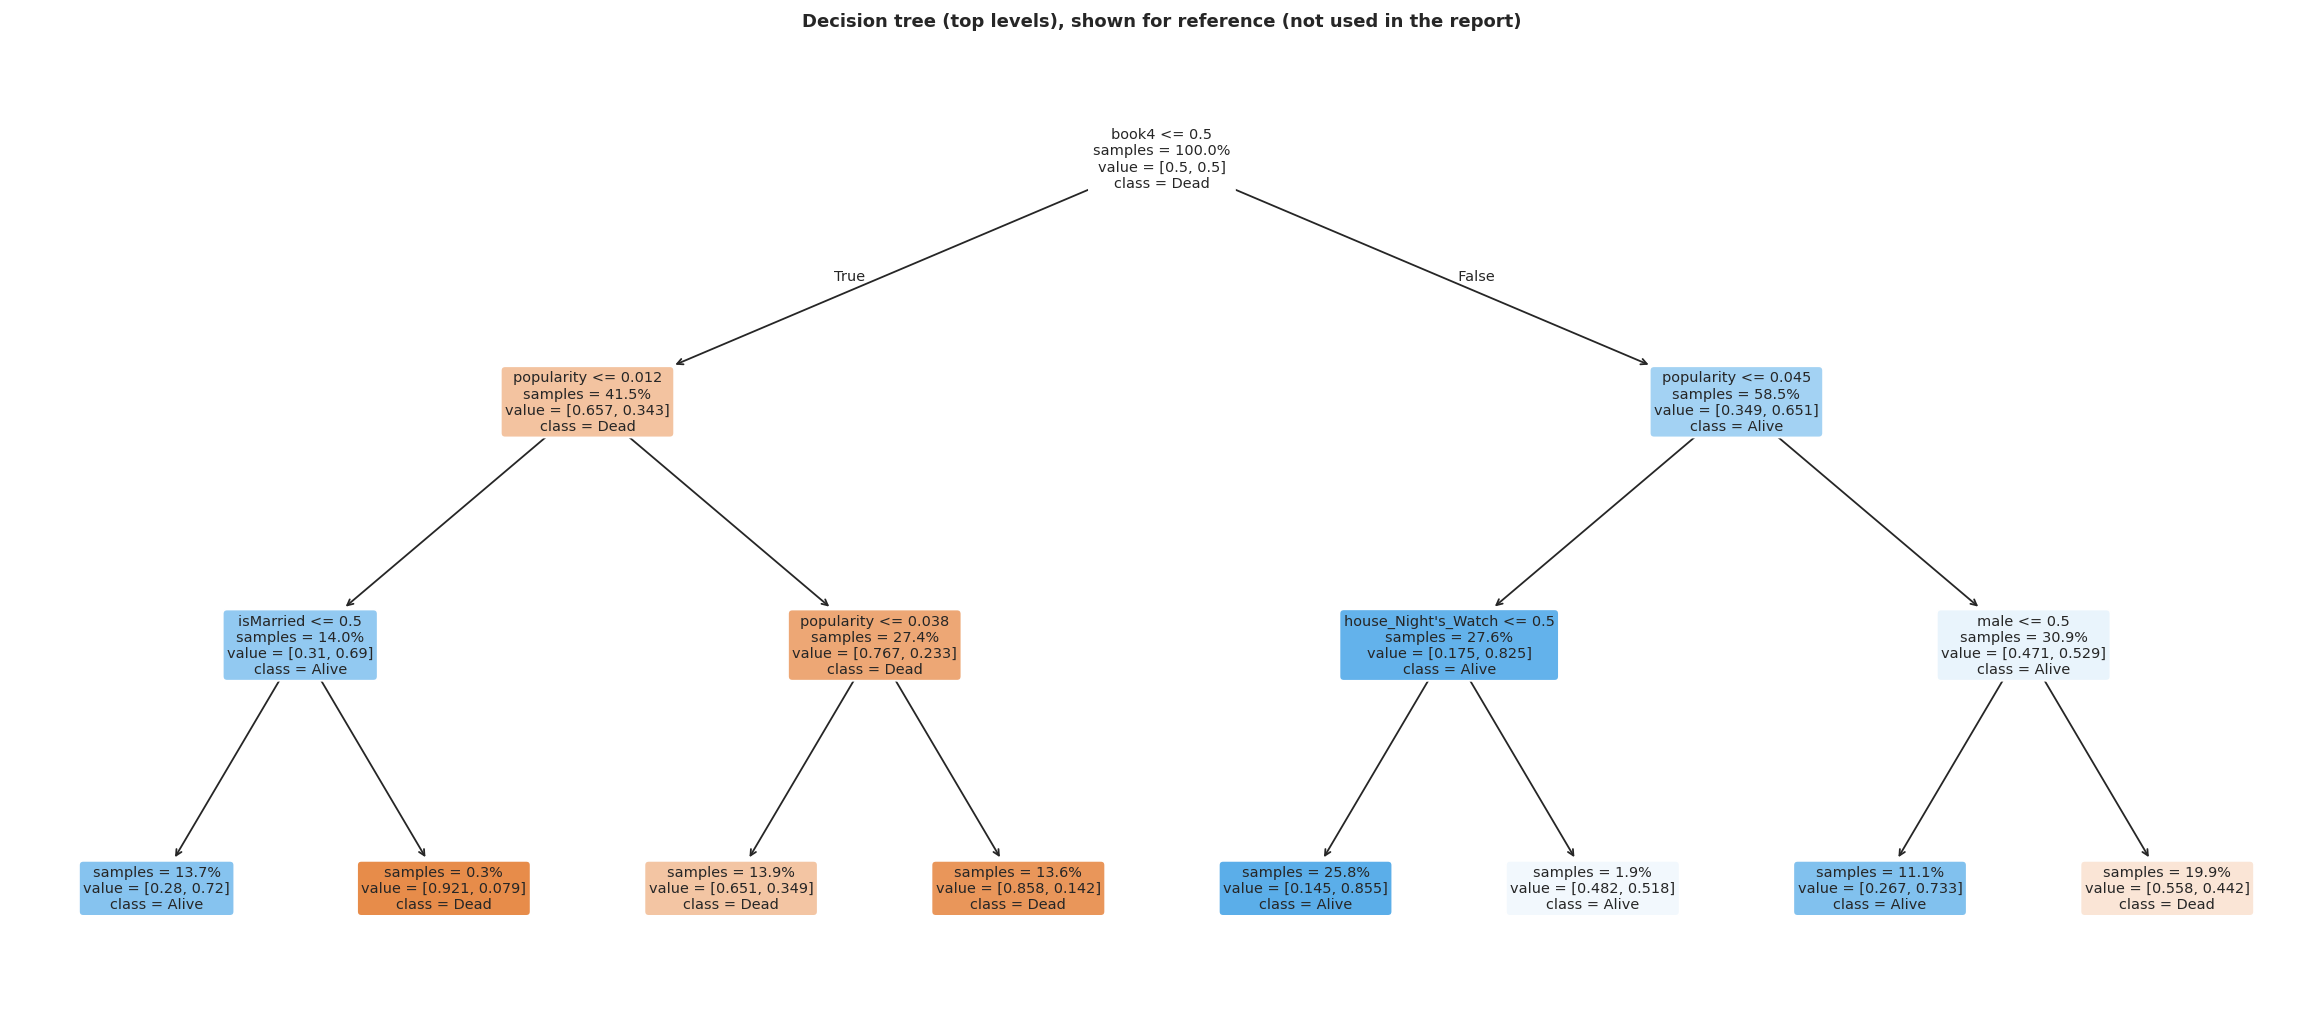

Top splits: book appearances, popularity and gender.


In [ ]:
# Decision tree (top levels) - kept for reference, not used in the report
dt = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=RS).fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(18, 8))
tree.plot_tree(dt, feature_names=list(X.columns), class_names=['Dead', 'Alive'],
               filled=True, rounded=True, fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title('Decision tree (top levels), shown for reference (not used in the report)',
             fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig16_tree.png', bbox_inches='tight')
plt.show()

print('Top splits: book appearances, popularity and gender.')

### 5.5 Random Forest — one of its trees (depth-limited for readability)

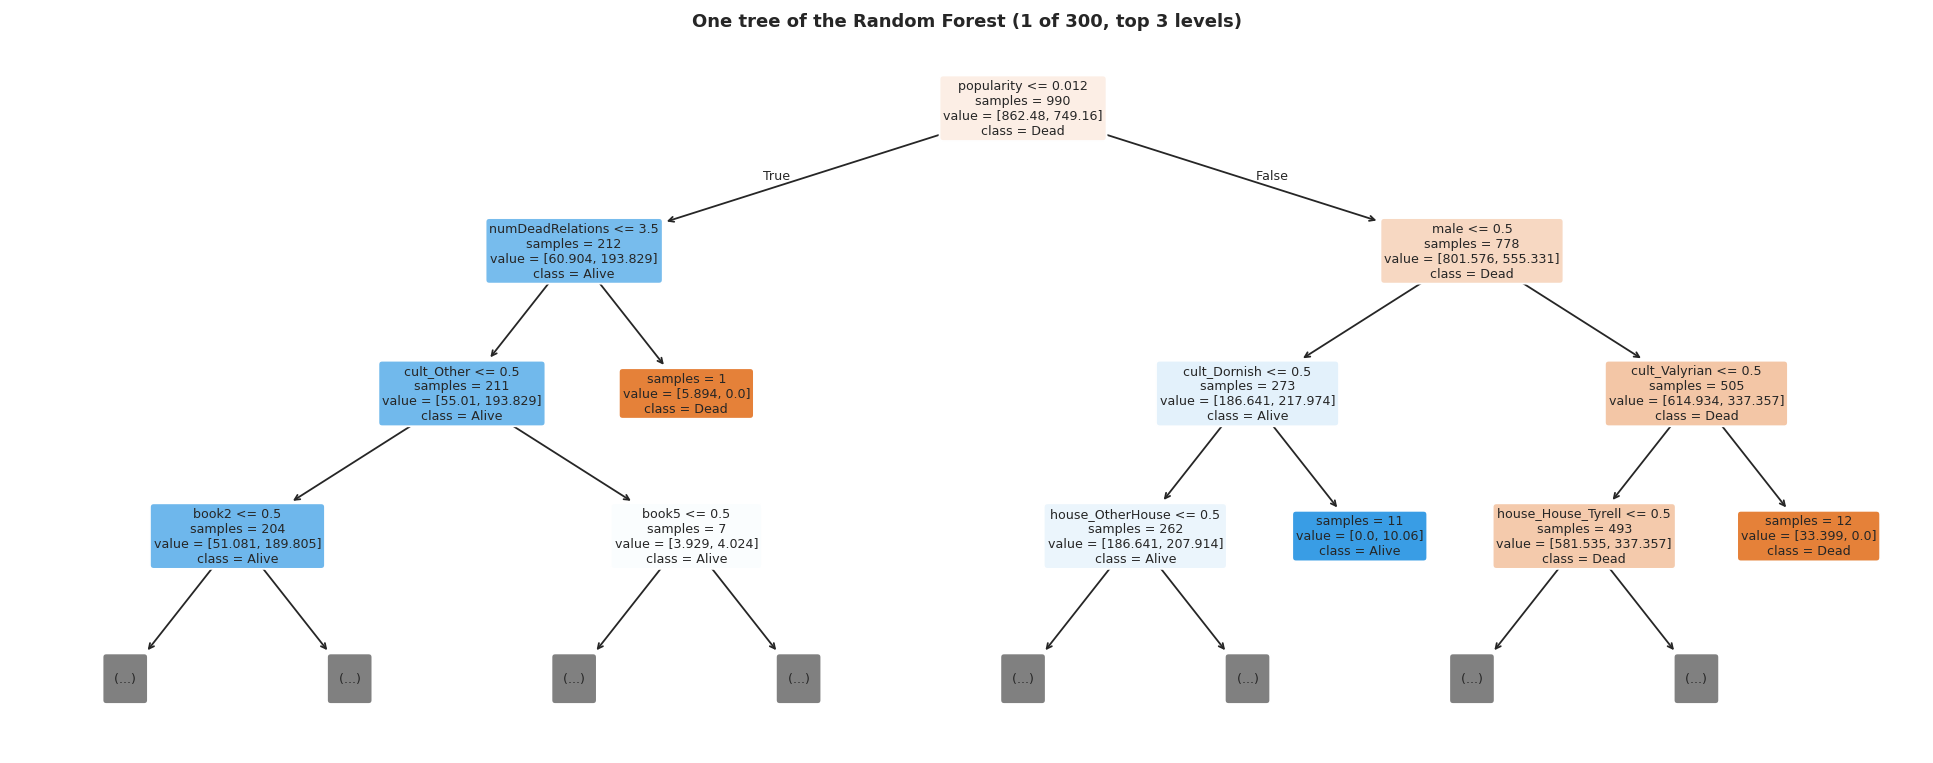

In [ ]:
# One single tree taken from the Random Forest (reference)
rf_full = best_models['RandomForest'].named_steps['m']
one_tree = rf_full.estimators_[0]

fig, ax = plt.subplots(figsize=(15, 6))
tree.plot_tree(one_tree, feature_names=list(X.columns), class_names=['Dead', 'Alive'],
               filled=True, rounded=True, fontsize=7, impurity=False, max_depth=3, ax=ax)
ax.set_title(f'One tree of the Random Forest (1 of {len(rf_full.estimators_)}, top 3 levels)',
             fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig17_rf_tree.png', bbox_inches='tight')
plt.show()

### 5.6 Naive Bayes — how it separates the classes (class-conditional means)

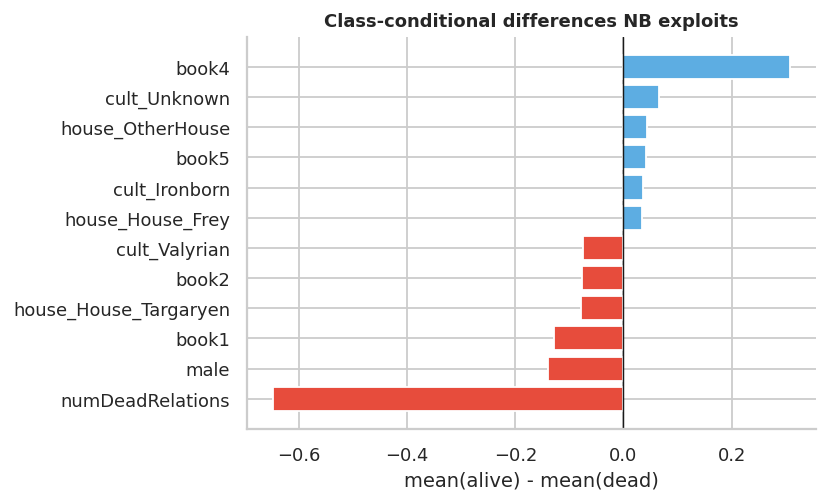

The features whose mean differs most between the two classes drive the Naive Bayes decision.


In [ ]:
# How Naive Bayes separates the classes: mean difference of each feature
mean_diff = (X_tr[y_tr == 1].mean() - X_tr[y_tr == 0].mean()).sort_values()
top = pd.concat([mean_diff.head(6), mean_diff.tail(6)])   # 6 most negative + 6 most positive

fig, ax = plt.subplots(figsize=(6.5, 4))
colors = ['#E74C3C' if v < 0 else '#5DADE2' for v in top.values]
ax.barh(top.index, top.values, color=colors, edgecolor='white')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('mean(alive) - mean(dead)')
ax.set_title('Class-conditional differences NB exploits', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig18_nb_separation.png', bbox_inches='tight')
plt.show()

print('The features whose mean differs most between the two classes drive the Naive Bayes decision.')

### 5.7 False negatives / positives, importance and minimal subset

In [ ]:
# False negatives / positives of the best model
cm = confusion_matrix(y_te, best.predict(X_te))
tn, fp, fn, tp = cm.ravel()
print(f'Best ({best_name}): TN={tn} FP={fp} FN={fn} TP={tp}')
print('The dead class is the harder one (lower recall).')

Best (RandomForest): TN=60 FP=39 FN=42 TP=249
The dead class is the harder one (lower recall).


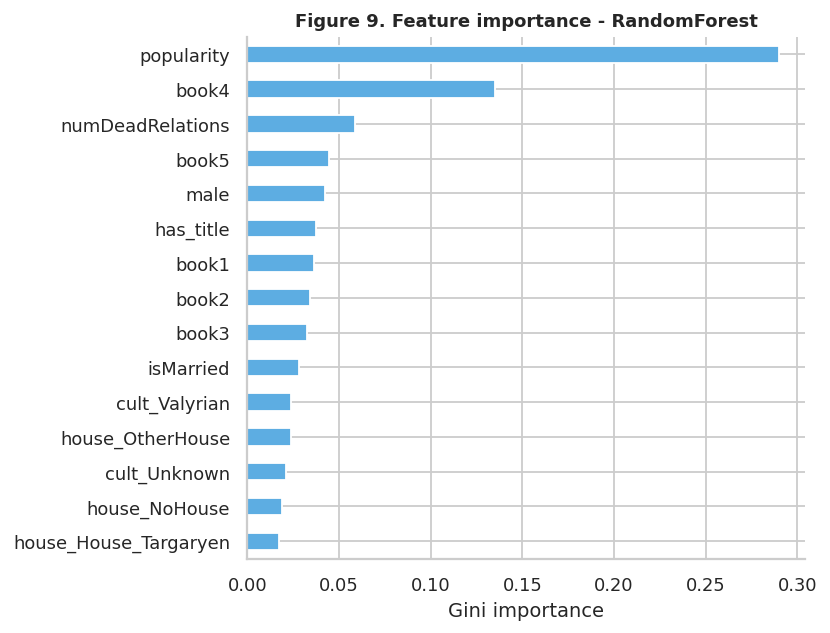

Top |corr| with target:
book4                    0.272
cult_Valyrian            0.220
numDeadRelations         0.201
popularity               0.200
house_House_Targaryen    0.184
book1                    0.142
male                     0.125
house_Night's_Watch      0.080


In [ ]:
# Figure 9 - feature importance of the best model
estimator = best.named_steps.get('m', best)
importance = pd.Series(getattr(estimator, 'feature_importances_', np.zeros(X.shape[1])),
                       index=X.columns).sort_values(ascending=False)
importance.to_csv(FIGURES_DIR / 'table_importance.csv')

fig, ax = plt.subplots(figsize=(6.5, 5))
importance.head(15).iloc[::-1].plot.barh(ax=ax, color='#5DADE2', edgecolor='white')
ax.set_title(f'Figure 9. Feature importance - {best_name}', fontsize=10, fontweight='bold')
ax.set_xlabel('Gini importance')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig19_importance.png', bbox_inches='tight')
plt.show()

# correlation of each feature with the target (used for the reduced models below)
corr_target = X_tr.corrwith(y_tr).abs().sort_values(ascending=False)
corr_target.to_csv(FIGURES_DIR / 'table_corr_target.csv')
print('Top |corr| with target:')
print(corr_target.head(8).round(3).to_string())

   subset  n  f1_macro
Full (32) 32     0.729
|r|>=0.10  7     0.650
|r|>=0.20  4     0.662
|r|>=0.25  1       NaN
|r|>=0.30  0       NaN


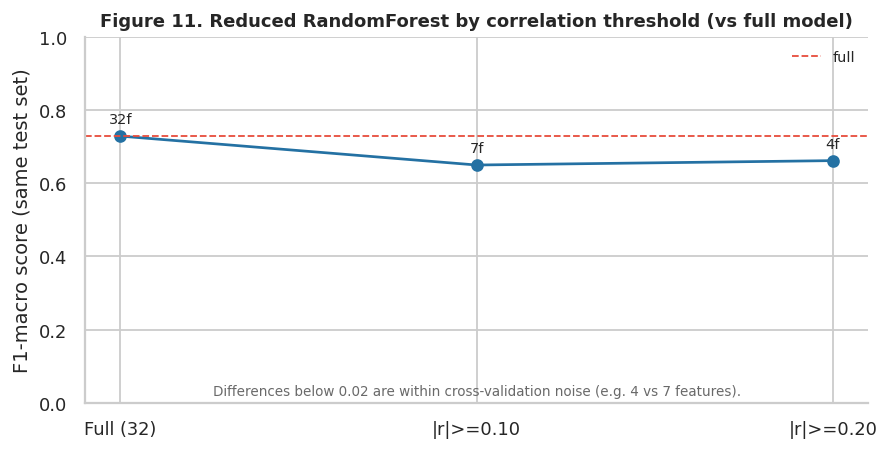

In [ ]:
# Figure 11 - smallest feature subset: keep features above a correlation threshold,
# retrain the SAME model and compare on the SAME test set with the SAME metric (F1-macro)
thresholds = [0.10, 0.20, 0.25, 0.30]
full_f1 = f1_score(y_te, best.predict(X_te), average='macro')

rows = [{'subset': f'Full ({X.shape[1]})', 'n': X.shape[1], 'f1_macro': round(full_f1, 3)}]
for t in thresholds:
    feats = corr_target[corr_target >= t].index.tolist()
    if len(feats) < 2:
        rows.append({'subset': f'|r|>={t:.2f}', 'n': len(feats), 'f1_macro': np.nan})
        continue
    reduced = clone(best)
    reduced.fit(X_tr[feats], y_tr)
    rows.append({'subset': f'|r|>={t:.2f}', 'n': len(feats),
                 'f1_macro': round(f1_score(y_te, reduced.predict(X_te[feats]), average='macro'), 3)})

reduced_df = pd.DataFrame(rows)
reduced_df.to_csv(FIGURES_DIR / 'table_reduced.csv', index=False)
print(reduced_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
valid = reduced_df.dropna()
ax.plot(valid['subset'], valid['f1_macro'], 'o-', color='#2471A3')
ax.axhline(full_f1, color='#E74C3C', ls='--', lw=1, label='full')
for _, r in valid.iterrows():
    ax.annotate(f"{int(r['n'])}f", (r['subset'], r['f1_macro']),
                textcoords='offset points', xytext=(0, 7), fontsize=8, ha='center')
ax.set_ylabel('F1-macro score (same test set)')
ax.set_ylim(0, 1)
ax.legend(fontsize=8, frameon=False)
ax.set_title(f'Figure 11. Reduced {best_name} by correlation threshold (vs full model)', fontsize=10, fontweight='bold')
ax.text(0.5, 0.02, 'Differences below 0.02 are within cross-validation noise (e.g. 4 vs 7 features).',
        transform=ax.transAxes, ha='center', fontsize=7.5, color='dimgray')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig20_reduced.png', bbox_inches='tight')
plt.show()